# Comparative metrics: baseline, SAHI, GNN, SAHI+GNN, and high-resolution inference

This notebook evaluates the existing YOLO26n `baseline2.0` checkpoint without retraining or modifying it. Validation is used only for confidence calibration and GNN training; test labels are reserved for final reporting.

The fixed test protocol is:
- class-aware, one-to-one matching at IoU 0.50;
- P/R/F1 at confidence 0.25;
- ranked AP at IoU 0.50 and the 0.50:0.95 range;
- separate class-wise and object-size-wise summaries;
- runtime and throughput for every executed method.

Run setup, audit, metric helpers, and baseline first. Run each optional experiment separately, because SAHI sweeps and high-resolution inference can be slow on CPU.

In [1]:
from pathlib import Path
import time
import random
import numpy as np
import pandas as pd
import torch
import yaml
from PIL import Image
import matplotlib.pyplot as plt
from ultralytics import YOLO

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

ROOT = Path.cwd()
if not (ROOT / "datasets" / "baseline2.0").is_dir() and (ROOT.parent / "datasets" / "baseline2.0").is_dir():
    ROOT = ROOT.parent

DATA_DIR = ROOT / "datasets" / "baseline2.0"
BASELINE_WEIGHTS = ROOT / "runs" / "detect" / "baseline2.0" / "weights" / "best.pt"
OUTPUT_CSV = ROOT / "metrics_comparison.csv"
CLASS_NAMES = ["3", "5", "6"]
NUM_CLASSES = len(CLASS_NAMES)
MAX_DET = 1499
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
FIXED_CONF = 0.25

if not BASELINE_WEIGHTS.is_file():
    raise FileNotFoundError(f"Baseline checkpoint not found: {BASELINE_WEIGHTS}")
for split in ("train", "valid", "test"):
    for kind in ("images", "labels"):
        folder = DATA_DIR / split / kind
        if not folder.is_dir():
            raise FileNotFoundError(f"Missing dataset folder: {folder}")

print(f"Root: {ROOT}")
print(f"Baseline: {BASELINE_WEIGHTS}")
print(f"Device: {DEVICE}")


Root: d:\AI-TOD.v2i.yolo26
Baseline: d:\AI-TOD.v2i.yolo26\runs\detect\baseline2.0\weights\best.pt
Device: cpu


## 1. Dataset and test-set audit

In [2]:
def list_images(folder):
    paths = sorted(p for p in folder.iterdir() if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"})
    if not paths:
        raise FileNotFoundError(f"No images found: {folder}")
    return paths

def read_ground_truth(image_path, label_dir):
    label_path = label_dir / f"{image_path.stem}.txt"
    if not label_path.is_file():
        raise FileNotFoundError(f"Missing label: {label_path}")
    with Image.open(image_path) as image:
        width, height = image.size
    objects = []
    if label_path.stat().st_size:
        for line in label_path.read_text(encoding="utf-8").splitlines():
            if not line.strip():
                continue
            fields = line.split()
            if len(fields) != 5:
                raise ValueError(f"Expected 5 YOLO fields: {label_path}")
            class_id = int(fields[0])
            xc, yc, bw, bh = map(float, fields[1:])
            box = np.array([
                (xc - bw / 2) * width, (yc - bh / 2) * height,
                (xc + bw / 2) * width, (yc + bh / 2) * height,
            ], dtype=np.float32)
            objects.append((class_id, box))
    return objects

test_paths = list_images(DATA_DIR / "test" / "images")
test_label_dir = DATA_DIR / "test" / "labels"
test_ground_truth = [read_ground_truth(p, test_label_dir) for p in test_paths]
valid_paths = list_images(DATA_DIR / "valid" / "images")
valid_label_dir = DATA_DIR / "valid" / "labels"
valid_ground_truth = [read_ground_truth(p, valid_label_dir) for p in valid_paths]

print(f"Validation: {len(valid_paths)} images")
print(f"Test: {len(test_paths)} images")
print("Test object counts:", {
    CLASS_NAMES[c]: sum(1 for objects in test_ground_truth for class_id, _ in objects if class_id == c)
    for c in range(NUM_CLASSES)
})


Validation: 600 images
Test: 300 images
Test object counts: {'3': 438, '5': 4135, '6': 639}


## 2. Shared matching, AP, and size-stratified metric functions

In [3]:
def box_iou_one_to_many(box, boxes):
    if len(boxes) == 0:
        return np.empty(0, dtype=np.float32)
    x1 = np.maximum(box[0], boxes[:, 0])
    y1 = np.maximum(box[1], boxes[:, 1])
    x2 = np.minimum(box[2], boxes[:, 2])
    y2 = np.minimum(box[3], boxes[:, 3])
    intersection = np.maximum(0, x2 - x1) * np.maximum(0, y2 - y1)
    area_a = max(0.0, float(box[2] - box[0])) * max(0.0, float(box[3] - box[1]))
    area_b = np.maximum(0, boxes[:, 2] - boxes[:, 0]) * np.maximum(0, boxes[:, 3] - boxes[:, 1])
    return intersection / np.maximum(area_a + area_b - intersection, 1e-12)

def match_records(records, ground_truth, iou_threshold=0.50, size_bucket=None):
    selected = []
    for image_index, class_id, score, box in records:
        if size_bucket is not None:
            area = max(0.0, box[2] - box[0]) * max(0.0, box[3] - box[1])
            low, high = size_bucket
            if not low <= area < high:
                continue
        selected.append((image_index, class_id, score, box))

    ordered = sorted(selected, key=lambda row: row[2], reverse=True)
    tp = np.zeros(len(ordered), dtype=np.float32)
    fp = np.zeros(len(ordered), dtype=np.float32)
    used = set()
    for row_index, (image_index, class_id, _, box) in enumerate(ordered):
        candidates = [(gt_index, gt_box) for gt_index, (gt_class, gt_box) in enumerate(ground_truth[image_index]) if gt_class == class_id]
        if size_bucket is not None:
            low, high = size_bucket
            candidates = [(gt_index, gt_box) for gt_index, gt_box in candidates
                          if low <= max(0.0, gt_box[2] - gt_box[0]) * max(0.0, gt_box[3] - gt_box[1]) < high]
        candidates = [(gt_index, gt_box) for gt_index, gt_box in candidates if (image_index, gt_index) not in used]
        if not candidates:
            fp[row_index] = 1
            continue
        gt_indices = [gt_index for gt_index, _ in candidates]
        gt_boxes = np.stack([gt_box for _, gt_box in candidates])
        ious = box_iou_one_to_many(box, gt_boxes)
        best = int(np.argmax(ious))
        if ious[best] >= iou_threshold:
            tp[row_index] = 1
            used.add((image_index, gt_indices[best]))
        else:
            fp[row_index] = 1
    return ordered, tp, fp

def average_precision(tp, fp, target_count):
    if target_count == 0:
        return 0.0
    cumulative_tp = np.cumsum(tp)
    cumulative_fp = np.cumsum(fp)
    recall = cumulative_tp / target_count
    precision = cumulative_tp / np.maximum(cumulative_tp + cumulative_fp, 1e-12)
    ap = 0.0
    recall_levels = np.linspace(0.0, 1.0, 101)
    for recall_level in recall_levels:
        candidates = precision[recall >= recall_level]
        ap += float(np.max(candidates)) if len(candidates) else 0.0
    return ap / len(recall_levels)

def target_count(ground_truth, class_id=None, size_bucket=None):
    count = 0
    for objects in ground_truth:
        for gt_class, box in objects:
            if class_id is not None and gt_class != class_id:
                continue
            area = max(0.0, box[2] - box[0]) * max(0.0, box[3] - box[1])
            if size_bucket is not None:
                low, high = size_bucket
                if not low <= area < high:
                    continue
            count += 1
    return count

def evaluate_records(records, ground_truth, conf=FIXED_CONF, size_bucket=None):
    selected = [row for row in records if row[2] >= conf]
    ordered, tp, fp = match_records(selected, ground_truth, 0.50, size_bucket)
    tp_count = int(tp.sum())
    fp_count = int(fp.sum())
    target_total = target_count(ground_truth, size_bucket=size_bucket)
    fn_count = target_total - tp_count
    precision = tp_count / max(tp_count + fp_count, 1)
    recall = tp_count / max(target_total, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)

    map50_values = []
    map5095_values = []
    class_metrics = {}
    for class_id, class_name in enumerate(CLASS_NAMES):
        class_records = [row for row in records if row[1] == class_id]
        class_targets = target_count(ground_truth, class_id, size_bucket)
        class_selected = [row for row in class_records if row[2] >= conf]
        _, class_tp, class_fp = match_records(class_selected, ground_truth, 0.50, size_bucket)
        class_tp_count = int(class_tp.sum())
        class_fp_count = int(class_fp.sum())
        class_fn = class_targets - class_tp_count
        class_precision = class_tp_count / max(class_tp_count + class_fp_count, 1)
        class_recall = class_tp_count / max(class_targets, 1)
        ap50 = average_precision(*match_records(class_records, ground_truth, 0.50, size_bucket)[1:], class_targets)
        ap_values = []
        for iou in np.arange(0.50, 0.96, 0.05):
            _, ap_tp, ap_fp = match_records(class_records, ground_truth, float(iou), size_bucket)
            ap_values.append(average_precision(ap_tp, ap_fp, class_targets))
        map50_values.append(ap50)
        map5095_values.append(float(np.mean(ap_values)))
        class_metrics[class_name] = {
            "precision": class_precision, "recall": class_recall,
            "tp": class_tp_count, "fp": class_fp_count, "fn": class_fn,
            "map50": ap50, "map50_95": float(np.mean(ap_values)),
        }
    map50 = float(np.mean(map50_values))
    map5095 = float(np.mean(map5095_values))
    return {
        "precision": precision, "recall": recall, "f1": f1,
        "map50": map50, "map50_95": map5095,
        "tp": tp_count, "fp": fp_count, "fn": fn_count,
        "classes": class_metrics,
    }

SIZE_BUCKETS = {
    "micro": (0, 32**2),
    "small": (32**2, 96**2),
    "medium": (96**2, 256**2),
    "large": (256**2, float("inf")),
}

METHOD_ROWS = []

def add_result(method, records, ground_truth=test_ground_truth, conf=FIXED_CONF, seconds=None, extra=None):
    metrics = evaluate_records(records, ground_truth, conf)
    size_metrics = {name: evaluate_records(records, ground_truth, conf, bucket)
                    for name, bucket in SIZE_BUCKETS.items()}
    row = {
        "method": method, "threshold": conf,
        "precision": metrics["precision"], "recall": metrics["recall"], "f1": metrics["f1"],
        "mAP50": metrics["map50"], "mAP50-95": metrics["map50_95"],
        "tp": metrics["tp"], "fp": metrics["fp"], "fn": metrics["fn"],
        "seconds": seconds,
    }
    if extra:
        row.update(extra)
    METHOD_ROWS.append(row)
    print(method, {k: round(v, 4) if isinstance(v, float) else v for k, v in row.items()})
    return metrics, size_metrics


## 3. Baseline and higher-resolution inference

In [4]:
def collect_yolo_records(model, image_paths, imgsz):
    records = []
    start = time.perf_counter()
    for image_index, image_path in enumerate(image_paths):
        result = model.predict(
            str(image_path), imgsz=imgsz, conf=0.001, max_det=MAX_DET,
            device=DEVICE, verbose=False,
        )[0]
        if result.boxes is not None:
            boxes = result.boxes.xyxy.cpu().numpy()
            scores = result.boxes.conf.cpu().numpy()
            classes = result.boxes.cls.cpu().numpy().astype(int)
            records.extend((image_index, int(class_id), float(score), box)
                           for box, score, class_id in zip(boxes, scores, classes))
    elapsed = time.perf_counter() - start
    return records, elapsed

baseline_model = YOLO(str(BASELINE_WEIGHTS))
baseline_records, baseline_seconds = collect_yolo_records(baseline_model, test_paths, 640)
baseline_metrics, baseline_sizes = add_result(
    "Baseline 640", baseline_records, seconds=baseline_seconds,
    extra={"ms_per_image": 1000 * baseline_seconds / len(test_paths)},
)

# Optional alternative: higher-resolution full-image inference.
high_resolution = {}
for resolution in (960, 1280):
    try:
        records, elapsed = collect_yolo_records(baseline_model, test_paths, resolution)
        name = f"Baseline {resolution}"
        _, sizes = add_result(name, records, seconds=elapsed,
                              extra={"ms_per_image": 1000 * elapsed / len(test_paths)})
        high_resolution[resolution] = (records, elapsed)
    except Exception as error:
        print(f"Skipping {resolution}px: {type(error).__name__}: {error}")


Baseline 640 {'method': 'Baseline 640', 'threshold': 0.25, 'precision': 0.688, 'recall': 0.4985, 'f1': 0.5781, 'mAP50': 0.4595, 'mAP50-95': 0.1534, 'tp': 2598, 'fp': 1178, 'fn': 2614, 'seconds': 101.4647, 'ms_per_image': 338.2158}
Baseline 960 {'method': 'Baseline 960', 'threshold': 0.25, 'precision': 0.7486, 'recall': 0.5267, 'f1': 0.6183, 'mAP50': 0.4971, 'mAP50-95': 0.1688, 'tp': 2745, 'fp': 922, 'fn': 2467, 'seconds': 178.6276, 'ms_per_image': 595.4253}
Baseline 1280 {'method': 'Baseline 1280', 'threshold': 0.25, 'precision': 0.7422, 'recall': 0.4568, 'f1': 0.5656, 'mAP50': 0.4397, 'mAP50-95': 0.1423, 'tp': 2381, 'fp': 827, 'fn': 2831, 'seconds': 296.7792, 'ms_per_image': 989.2639}


## 4. SAHI tile-size and overlap sweep

In [6]:
try:
    from sahi import AutoDetectionModel
    from sahi.predict import get_sliced_prediction
except ImportError as error:
    raise ImportError("Install SAHI first: pip install sahi") from error

SAHI_CONFIGS = [
    (160, 0.10), (160, 0.25), (160, 0.50),
    (320, 0.10), (320, 0.25), (320, 0.50),
    (480, 0.10), (480, 0.25), (480, 0.50),
]
sahi_results = {}

for tile_size, overlap in SAHI_CONFIGS:
    detection_model = AutoDetectionModel.from_pretrained(
        model_type="ultralytics",
        model_path=str(BASELINE_WEIGHTS),
        confidence_threshold=0.001,
        device=DEVICE,
        image_size=640,
    )
    detection_model.model.overrides["max_det"] = MAX_DET
    records = []
    start = time.perf_counter()
    for image_index, image_path in enumerate(test_paths):
        prediction = get_sliced_prediction(
            str(image_path),
            detection_model,
            slice_height=tile_size,
            slice_width=tile_size,
            overlap_height_ratio=overlap,
            overlap_width_ratio=overlap,
            perform_standard_pred=True,
            postprocess_type="NMS",
            postprocess_match_threshold=0.65,
            verbose=0,
        )
        for detection in prediction.object_prediction_list:
            records.append((
                image_index,
                int(detection.category.id),
                float(detection.score.value),
                np.asarray(detection.bbox.to_xyxy(), dtype=np.float32),
            ))
    elapsed = time.perf_counter() - start
    name = f"SAHI {tile_size}px o={overlap:.2f}"
    metrics, sizes = add_result(name, records, seconds=elapsed,
                                extra={"tile_size": tile_size, "overlap": overlap,
                                       "ms_per_image": 1000 * elapsed / len(test_paths)})
    sahi_results[(tile_size, overlap)] = (records, elapsed, metrics, sizes)

pd.DataFrame(METHOD_ROWS).to_csv(OUTPUT_CSV, index=False)
print(f"Saved intermediate comparison table: {OUTPUT_CSV}")


SAHI 160px o=0.10 {'method': 'SAHI 160px o=0.10', 'threshold': 0.25, 'precision': 0.6624, 'recall': 0.4939, 'f1': 0.5658, 'mAP50': 0.4173, 'mAP50-95': 0.1353, 'tp': 2574, 'fp': 1312, 'fn': 2638, 'seconds': 2694.1339, 'tile_size': 160, 'overlap': 0.1, 'ms_per_image': 8980.4465}
SAHI 160px o=0.25 {'method': 'SAHI 160px o=0.25', 'threshold': 0.25, 'precision': 0.6595, 'recall': 0.4935, 'f1': 0.5645, 'mAP50': 0.4166, 'mAP50-95': 0.1355, 'tp': 2572, 'fp': 1328, 'fn': 2640, 'seconds': 4205.7276, 'tile_size': 160, 'overlap': 0.25, 'ms_per_image': 14019.092}
SAHI 160px o=0.50 {'method': 'SAHI 160px o=0.50', 'threshold': 0.25, 'precision': 0.6509, 'recall': 0.4933, 'f1': 0.5612, 'mAP50': 0.412, 'mAP50-95': 0.1343, 'tp': 2571, 'fp': 1379, 'fn': 2641, 'seconds': 3782.8499, 'tile_size': 160, 'overlap': 0.5, 'ms_per_image': 12609.4996}
SAHI 320px o=0.10 {'method': 'SAHI 320px o=0.10', 'threshold': 0.25, 'precision': 0.6731, 'recall': 0.5562, 'f1': 0.6091, 'mAP50': 0.4613, 'mAP50-95': 0.154, 'tp': 2

## 5. GNN post-processing

In [7]:
import torch.nn as nn
import torch.nn.functional as F

class GraphSAGELayer(nn.Module):
    def __init__(self, input_size, output_size):
        super().__init__()
        self.self_linear = nn.Linear(input_size, output_size)
        self.neighbor_linear = nn.Linear(input_size, output_size)

    def forward(self, x, edges):
        source, target = edges
        aggregate = torch.zeros_like(x)
        degree = torch.zeros((len(x), 1), dtype=x.dtype, device=x.device)
        if source.numel():
            aggregate.index_add_(0, target, x[source])
            degree.index_add_(0, target, torch.ones((len(target), 1), dtype=x.dtype, device=x.device))
        aggregate = aggregate / degree.clamp_min(1.0)
        return F.relu(self.self_linear(x) + self.neighbor_linear(aggregate))

class DetectionGraphScorer(nn.Module):
    def __init__(self, input_size=5 + NUM_CLASSES, hidden_size=32):
        super().__init__()
        self.layer1 = GraphSAGELayer(input_size, hidden_size)
        self.layer2 = GraphSAGELayer(hidden_size, hidden_size)
        self.dropout = nn.Dropout(0.15)
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, x, edges):
        x = self.dropout(self.layer1(x, edges))
        x = self.dropout(self.layer2(x, edges))
        return self.output(x).squeeze(-1)

def candidate_labels(detections, ground_truth, iou_threshold=0.5):
    labels = np.zeros(len(detections["scores"]), dtype=np.float32)
    matched = set()
    for det_index in np.argsort(-detections["scores"]):
        class_id = int(detections["classes"][det_index])
        candidates = [(gt_index, gt_box) for gt_index, (gt_class, gt_box) in enumerate(ground_truth)
                      if gt_class == class_id and gt_index not in matched]
        if not candidates:
            continue
        gt_indices = [gt_index for gt_index, _ in candidates]
        gt_boxes = np.stack([gt_box for _, gt_box in candidates])
        ious = box_iou_one_to_many(detections["boxes"][det_index], gt_boxes)
        best = int(np.argmax(ious))
        if ious[best] >= iou_threshold:
            labels[det_index] = 1.0
            matched.add(gt_indices[best])
    return labels

def collect_full_detections(image_paths, imgsz=640):
    detections = []
    for image_path in image_paths:
        result = baseline_model.predict(
            str(image_path), imgsz=imgsz, conf=0.001, max_det=MAX_DET,
            device=DEVICE, verbose=False,
        )[0]
        if result.boxes is None:
            detections.append({
                "boxes": np.empty((0, 4), np.float32),
                "scores": np.empty(0, np.float32),
                "classes": np.empty(0, np.int64),
            })
        else:
            detections.append({
                "boxes": result.boxes.xyxy.cpu().numpy().astype(np.float32),
                "scores": result.boxes.conf.cpu().numpy().astype(np.float32),
                "classes": result.boxes.cls.cpu().numpy().astype(np.int64),
            })
    return detections

def make_graph(detections, image_path, labels=None, neighbors=8):
    with Image.open(image_path) as image:
        width, height = image.size
    boxes = detections["boxes"]
    scores = detections["scores"]
    classes = detections["classes"]
    n = len(scores)
    if n == 0:
        return {
            "x": torch.empty((0, 5 + NUM_CLASSES)),
            "y": torch.empty((0,), dtype=torch.float32) if labels is not None else None,
            "edges": torch.empty((2, 0), dtype=torch.long),
        }
    normalized = boxes / np.array([width, height, width, height], dtype=np.float32)
    one_hot = np.eye(NUM_CLASSES, dtype=np.float32)[classes]
    x = torch.from_numpy(np.concatenate([normalized, scores[:, None], one_hot], axis=1))
    centers = torch.from_numpy((normalized[:, :2] + normalized[:, 2:]) / 2)
    if n == 1:
        edges = torch.empty((2, 0), dtype=torch.long)
    else:
        distances = torch.cdist(centers, centers)
        distances.fill_diagonal_(float("inf"))
        k = min(neighbors, n - 1)
        neighbor_indices = torch.topk(distances, k=k, largest=False).indices
        targets = torch.arange(n).repeat_interleave(k)
        sources = neighbor_indices.reshape(-1)
        edges = torch.stack([sources, targets])
    y = torch.from_numpy(labels) if labels is not None else None
    return {"x": x, "y": y, "edges": edges}

valid_detections = collect_full_detections(valid_paths)
valid_graphs = [
    make_graph(detections, image_path,
               candidate_labels(detections, read_ground_truth(image_path, valid_label_dir)))
    for image_path, detections in zip(valid_paths, valid_detections)
]

permutation = np.random.default_rng(SEED).permutation(len(valid_paths))
fit_count = int(0.70 * len(valid_paths))
fit_graphs = [valid_graphs[i] for i in permutation[:fit_count] if len(valid_graphs[i]["y"]) > 0]
calibration_indices = permutation[fit_count:].tolist()

features, labels, edge_parts = [], [], []
offset = 0
for graph in fit_graphs:
    count = len(graph["x"])
    if count == 0:
        continue
    features.append(graph["x"])
    labels.append(graph["y"])
    if graph["edges"].numel():
        edge_parts.append(graph["edges"] + offset)
    offset += count

positive_count = sum(int(y.sum()) for y in labels)
negative_count = sum(len(y) - int(y.sum()) for y in labels)
if positive_count:
    pos_weight = min(20.0, negative_count / positive_count)
    scorer = DetectionGraphScorer().to(DEVICE)
    optimizer = torch.optim.AdamW(scorer.parameters(), lr=1e-3, weight_decay=1e-4)
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight, device=DEVICE))
    batch_graphs = fit_graphs
    GNN_EPOCHS = 15
    for epoch in range(GNN_EPOCHS):
        scorer.train()
        epoch_losses = []
        rng = np.random.default_rng(SEED + epoch)
        order = rng.permutation(len(batch_graphs))
        for start in range(0, len(order), 16):
            batch = [batch_graphs[i] for i in order[start:start + 16]]
            bx, by, be = [], [], []
            boffset = 0
            batch_edges = []
            for graph in batch:
                if len(graph["x"]) == 0:
                    continue
                bx.append(graph["x"])
                by.append(graph["y"])
                if graph["edges"].numel():
                    batch_edges.append(graph["edges"] + boffset)
                boffset += len(graph["x"])
            if not bx:
                continue
            bx = torch.cat(bx).to(DEVICE)
            by = torch.cat(by).to(DEVICE)
            be = torch.cat(batch_edges, dim=1).to(DEVICE) if batch_edges else torch.empty((2, 0), dtype=torch.long, device=DEVICE)
            logits = scorer(bx, be)
            loss = criterion(logits, by)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            epoch_losses.append(float(loss.item()))
        if epoch_losses:
            print(f"GNN epoch {epoch + 1:02d}/{GNN_EPOCHS}: loss={np.mean(epoch_losses):.4f}")

    def score_detections(detections, image_paths):
        scorer.eval()
        output = []
        with torch.no_grad():
            for detections_item, image_path in zip(detections, image_paths):
                graph = make_graph(detections_item, image_path)
                x = graph["x"].to(DEVICE)
                edges = graph["edges"].to(DEVICE)
                scores = torch.sigmoid(scorer(x, edges)).cpu().numpy() if len(x) else np.empty(0)
                output.append(scores)
        return output

    valid_gnn_scores = score_detections(valid_detections, valid_paths)
    test_full_detections = collect_full_detections(test_paths)
    test_gnn_scores = score_detections(test_full_detections, test_paths)
    gnn_records = [
        (image_index, int(class_id), float(score), box)
        for image_index, (detections_item, scores) in enumerate(zip(test_full_detections, test_gnn_scores))
        for box, class_id, score in zip(detections_item["boxes"], detections_item["classes"], scores)
    ]
    gnn_metrics, gnn_sizes = add_result("YOLO + GNN", gnn_records,
                                        extra={"ms_per_image": None})
else:
    gnn_records = None
    print("GNN skipped: no positive candidates in the validation-fit subset.")


GNN epoch 01/15: loss=1.2256
GNN epoch 02/15: loss=1.1940
GNN epoch 03/15: loss=1.1818
GNN epoch 04/15: loss=1.1629
GNN epoch 05/15: loss=1.1118
GNN epoch 06/15: loss=0.9704
GNN epoch 07/15: loss=0.8914
GNN epoch 08/15: loss=0.7956
GNN epoch 09/15: loss=0.7354
GNN epoch 10/15: loss=0.6824
GNN epoch 11/15: loss=0.6814
GNN epoch 12/15: loss=0.6445
GNN epoch 13/15: loss=0.6407
GNN epoch 14/15: loss=0.6115
GNN epoch 15/15: loss=0.5973
YOLO + GNN {'method': 'YOLO + GNN', 'threshold': 0.25, 'precision': 0.3513, 'recall': 0.6769, 'f1': 0.4626, 'mAP50': 0.4471, 'mAP50-95': 0.148, 'tp': 3528, 'fp': 6514, 'fn': 1684, 'seconds': None, 'ms_per_image': None}


## 6. Combine SAHI detections with the trained GNN

In [8]:
if "scorer" not in globals():
    print("Run the GNN cell first.")
elif "sahi_results" not in globals():
    print("Run the SAHI sweep cell first.")
else:
    sahi_gnn_results = {}
    scorer.eval()
    for (tile_size, overlap), (sahi_records, elapsed, _, _) in sahi_results.items():
        detections_by_image = [
            {"boxes": np.empty((0, 4), dtype=np.float32),
             "scores": np.empty(0, dtype=np.float32),
             "classes": np.empty(0, dtype=np.int64)}
            for _ in test_paths
        ]
        for image_index, class_id, score, box in sahi_records:
            detection = detections_by_image[image_index]
            detection["boxes"] = np.vstack([detection["boxes"], box])
            detection["scores"] = np.concatenate([detection["scores"], np.array([score], dtype=np.float32)])
            detection["classes"] = np.concatenate([detection["classes"], np.array([class_id], dtype=np.int64)])

        combined_records = []
        start = time.perf_counter()
        with torch.no_grad():
            for image_index, (detection, image_path) in enumerate(zip(detections_by_image, test_paths)):
                graph = make_graph(detection, image_path)
                x = graph["x"].to(DEVICE)
                edges = graph["edges"].to(DEVICE)
                gnn_scores = torch.sigmoid(scorer(x, edges)).cpu().numpy() if len(x) else np.empty(0)
                combined_records.extend(
                    (image_index, int(class_id), float(score), box)
                    for box, class_id, score in zip(detection["boxes"], detection["classes"], gnn_scores)
                )
        gnn_elapsed = time.perf_counter() - start
        name = f"SAHI+GNN {tile_size}px o={overlap:.2f}"
        metrics, sizes = add_result(
            name, combined_records, seconds=elapsed + gnn_elapsed,
            extra={"tile_size": tile_size, "overlap": overlap,
                   "ms_per_image": 1000 * (elapsed + gnn_elapsed) / len(test_paths)},
        )
        sahi_gnn_results[(tile_size, overlap)] = (combined_records, elapsed + gnn_elapsed, metrics, sizes)

pd.DataFrame(METHOD_ROWS).to_csv(OUTPUT_CSV, index=False)


SAHI+GNN 160px o=0.10 {'method': 'SAHI+GNN 160px o=0.10', 'threshold': 0.25, 'precision': 0.3716, 'recall': 0.6435, 'f1': 0.4711, 'mAP50': 0.4071, 'mAP50-95': 0.1298, 'tp': 3354, 'fp': 5673, 'fn': 1858, 'seconds': 2696.2724, 'tile_size': 160, 'overlap': 0.1, 'ms_per_image': 8987.5746}
SAHI+GNN 160px o=0.25 {'method': 'SAHI+GNN 160px o=0.25', 'threshold': 0.25, 'precision': 0.3692, 'recall': 0.6418, 'f1': 0.4687, 'mAP50': 0.407, 'mAP50-95': 0.1307, 'tp': 3345, 'fp': 5716, 'fn': 1867, 'seconds': 4207.9269, 'tile_size': 160, 'overlap': 0.25, 'ms_per_image': 14026.423}
SAHI+GNN 160px o=0.50 {'method': 'SAHI+GNN 160px o=0.50', 'threshold': 0.25, 'precision': 0.3669, 'recall': 0.6404, 'f1': 0.4665, 'mAP50': 0.4014, 'mAP50-95': 0.1292, 'tp': 3338, 'fp': 5761, 'fn': 1874, 'seconds': 3786.5336, 'tile_size': 160, 'overlap': 0.5, 'ms_per_image': 12621.7785}
SAHI+GNN 320px o=0.10 {'method': 'SAHI+GNN 320px o=0.10', 'threshold': 0.25, 'precision': 0.3504, 'recall': 0.702, 'f1': 0.4675, 'mAP50': 0.4

## 7. Threshold sweep and final comparison

               method  threshold  precision   recall       f1    mAP50  mAP50-95   tp   fp   fn     seconds  ms_per_image  tile_size  overlap
         Baseline 640       0.25   0.688030 0.498465 0.578104 0.459481  0.153442 2598 1178 2614  101.464734    338.215781        NaN      NaN
         Baseline 960       0.25   0.748568 0.526669 0.618313 0.497075  0.168802 2745  922 2467  178.627599    595.425329        NaN      NaN
        Baseline 1280       0.25   0.742207 0.456830 0.565558 0.439708  0.142306 2381  827 2831  296.779156    989.263852        NaN      NaN
    SAHI 160px o=0.10       0.25   0.662378 0.493860 0.565839 0.417306  0.135264 2574 1312 2638 2694.133950   8980.446498      160.0     0.10
    SAHI 160px o=0.25       0.25   0.659487 0.493477 0.564530 0.416563  0.135524 2572 1328 2640 4205.727612  14019.092041      160.0     0.25
    SAHI 160px o=0.50       0.25   0.650886 0.493285 0.561231 0.412006  0.134251 2571 1379 2641 3782.849878  12609.499593      160.0     0.50
    SA

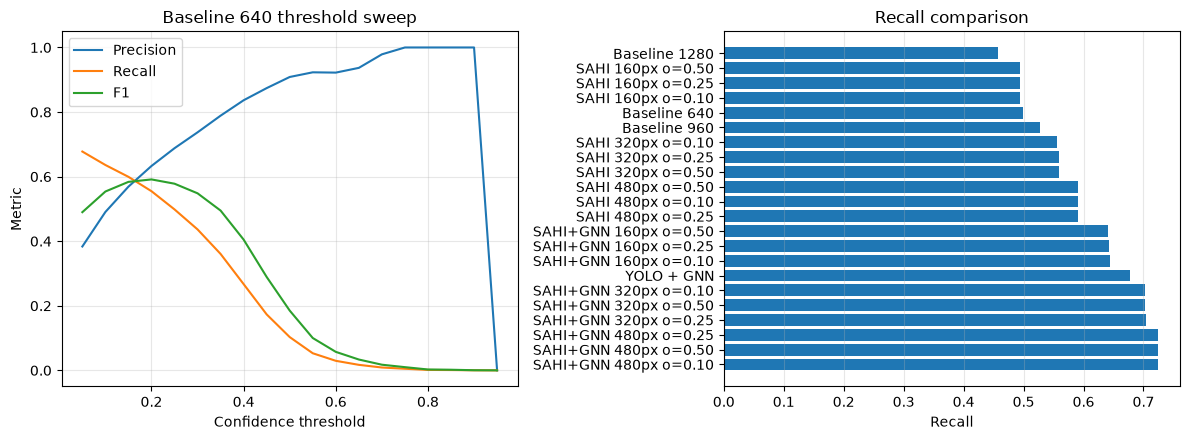

In [9]:
threshold_values = np.arange(0.05, 0.96, 0.05)

def threshold_sweep(records, ground_truth=test_ground_truth):
    rows = []
    for threshold in threshold_values:
        metrics = evaluate_records(records, ground_truth, float(threshold))
        rows.append({
            "threshold": float(threshold),
            "precision": metrics["precision"],
            "recall": metrics["recall"],
            "f1": metrics["f1"],
            "mAP50": metrics["map50"],
            "mAP50-95": metrics["map50_95"],
            "fp": metrics["fp"],
            "fn": metrics["fn"],
        })
    return pd.DataFrame(rows)

baseline_sweep = threshold_sweep(baseline_records)
baseline_sweep.insert(0, "method", "Baseline 640")

comparison = pd.DataFrame(METHOD_ROWS)
comparison.to_csv(OUTPUT_CSV, index=False)
print(comparison.to_string(index=False))
print(f"Saved: {OUTPUT_CSV}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(baseline_sweep["threshold"], baseline_sweep["precision"], label="Precision")
axes[0].plot(baseline_sweep["threshold"], baseline_sweep["recall"], label="Recall")
axes[0].plot(baseline_sweep["threshold"], baseline_sweep["f1"], label="F1")
axes[0].set_xlabel("Confidence threshold")
axes[0].set_ylabel("Metric")
axes[0].set_title("Baseline 640 threshold sweep")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

if len(comparison):
    ordered = comparison.sort_values("recall", ascending=False)
    axes[1].barh(ordered["method"], ordered["recall"])
    axes[1].set_xlabel("Recall")
    axes[1].set_title("Recall comparison")
    axes[1].grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


## 8. Size-stratified and qualitative analysis

In [10]:
size_rows = []
method_records = {"Baseline 640": baseline_records}
if "gnn_records" in globals() and gnn_records is not None:
    method_records["YOLO + GNN"] = gnn_records
for (tile_size, overlap), (records, _, _, _) in globals().get("sahi_results", {}).items():
    method_records[f"SAHI {tile_size}px o={overlap:.2f}"] = records
for (tile_size, overlap), (records, _, _, _) in globals().get("sahi_gnn_results", {}).items():
    method_records[f"SAHI+GNN {tile_size}px o={overlap:.2f}"] = records
for method_name, records in method_records.items():
    for size_name, bucket in SIZE_BUCKETS.items():
        metrics = evaluate_records(records, test_ground_truth, FIXED_CONF, bucket)
        size_rows.append({
            "method": method_name, "size": size_name,
            "precision": metrics["precision"], "recall": metrics["recall"],
            "f1": metrics["f1"], "tp": metrics["tp"], "fp": metrics["fp"], "fn": metrics["fn"],
        })

size_table = pd.DataFrame(size_rows)
if not size_table.empty:
    print(size_table.pivot(index="method", columns="size", values="recall").to_string())
    size_table.to_csv(ROOT / "metrics_size_stratified.csv", index=False)

# Select a dense image with many ground-truth objects for visual failure analysis.
image_scores = [len(objects) for objects in test_ground_truth]
sample_index = int(np.argmax(image_scores))
sample_path = test_paths[sample_index]
print("Qualitative sample:", sample_path)
print("Ground-truth objects:", len(test_ground_truth[sample_index]))

baseline_model.predict(str(sample_path), imgsz=640, conf=FIXED_CONF,
                       max_det=MAX_DET, device=DEVICE, save=True,
                       project=str(ROOT / "metrics_visuals"),
                       name="baseline", exist_ok=True)


size                   large  medium     micro     small
method                                                  
Baseline 640             0.0     0.0  0.495728  0.467742
SAHI 160px o=0.10        0.0     0.0  0.491262  0.467742
SAHI 160px o=0.25        0.0     0.0  0.490874  0.467742
SAHI 160px o=0.50        0.0     0.0  0.490680  0.467742
SAHI 320px o=0.10        0.0     0.0  0.554369  0.467742
SAHI 320px o=0.25        0.0     0.0  0.556505  0.467742
SAHI 320px o=0.50        0.0     0.0  0.557864  0.467742
SAHI 480px o=0.10        0.0     0.0  0.589320  0.483871
SAHI 480px o=0.25        0.0     0.0  0.589320  0.483871
SAHI 480px o=0.50        0.0     0.0  0.589320  0.483871
SAHI+GNN 160px o=0.10    0.0     0.0  0.641553  0.532258
SAHI+GNN 160px o=0.25    0.0     0.0  0.640000  0.532258
SAHI+GNN 160px o=0.50    0.0     0.0  0.638641  0.532258
SAHI+GNN 320px o=0.10    0.0     0.0  0.700388  0.532258
SAHI+GNN 320px o=0.25    0.0     0.0  0.702330  0.532258
SAHI+GNN 320px o=0.50    0.0   

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 colors: None
 depth: None
 keypoints: None
 masks: None
 names: {0: '3', 1: '5', 2: '6'}
 obb: None
 orig_img: array([[[ 67,  50,  47],
         [ 67,  50,  47],
         [ 67,  50,  47],
         ...,
         [124,  88,  64],
         [122,  86,  62],
         [120,  84,  60]],
 
        [[ 67,  50,  47],
         [ 67,  50,  47],
         [ 67,  50,  47],
         ...,
         [118,  82,  58],
         [114,  78,  54],
         [112,  76,  52]],
 
        [[ 64,  49,  46],
         [ 65,  50,  47],
         [ 65,  50,  47],
         ...,
         [108,  74,  51],
         [105,  71,  48],
         [105,  71,  48]],
 
        ...,
 
        [[ 94,  86,  69],
         [ 76,  68,  51],
         [ 65,  57,  40],
         ...,
         [ 44,  32,  20],
         [ 43,  31,  19],
         [ 43,  31,  19]],
 
        [[ 87,  79,  62],
         [ 80,  72,  55],
         [ 72,  64, 